<a href="https://colab.research.google.com/github/ayushranjan1808/breast-cancer-diagonisis-ml-model/blob/main/breast_cancer_diagonisis_ml_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# UCI se Breast Cancer ka data mangwana
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/breast-cancer-wisconsin.data"
columns = ['ID', 'Clump_Thickness', 'Cell_Size', 'Cell_Shape', 'Adhesion', 'Epithelial_Size', 'Bare_Nuclei', 'Chromatin', 'Nucleoli', 'Mitoses', 'Class']

df = pd.read_csv(url, names=columns)

# Pehle 10 patients ka data dekhna
df.head(10)

,ID,Clump_Thickness,Cell_Size,Cell_Shape,Adhesion,Epithelial_Size,Bare_Nuclei,Chromatin,Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2
5,1017122,8,10,10,8,7,10,9,7,1,4
6,1018099,1,1,1,1,2,10,3,1,1,2
7,1018561,2,1,2,1,2,1,3,1,1,2
8,1033078,2,1,1,1,2,1,1,1,5,2
9,1033078,4,2,1,1,2,1,2,1,1,2


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   ID               699 non-null    int64 
 1   Clump_Thickness  699 non-null    int64 
 2   Cell_Size        699 non-null    int64 
 3   Cell_Shape       699 non-null    int64 
 4   Adhesion         699 non-null    int64 
 5   Epithelial_Size  699 non-null    int64 
 6   Bare_Nuclei      699 non-null    object
 7   Chromatin        699 non-null    int64 
 8   Nucleoli         699 non-null    int64 
 9   Mitoses          699 non-null    int64 
 10  Class            699 non-null    int64 
dtypes: int64(10), object(1)
memory usage: 60.2+ KB


In [ ]:
# Bare_Nuclei column mein kaun-kaun si unique values hain, woh dekhna
print(df['Bare_Nuclei'].unique())

# Kitne rows mein '?' chhupa hai, woh ginna
print("Question mark ('?') wale patients ki ginti:", (df['Bare_Nuclei'] == '?').sum())

['1' '10' '2' '4' '3' '9' '7' '?' '5' '8' '6']
Question mark ('?') wale patients ki ginti: 16


In [ ]:
import numpy as np

# 1. '?' ko NaN (Missing) mein badalna aur poore column ko Number (float) banana
df['Bare_Nuclei'] = df['Bare_Nuclei'].replace('?', np.nan).astype(float)

# 2. Khaali jagah (NaN) ko Bare_Nuclei ke Median (beech ki value) se bharna
median_val = df['Bare_Nuclei'].median()
df['Bare_Nuclei'] = df['Bare_Nuclei'].fillna(median_val)

# 3. ID column ko hatana (kyunki ID se cancer ka koi lena-dena nahi)
df = df.drop('ID', axis=1)

# 4. Class mein 2 (Benign) ko 0 aur 4 (Malignant) ko 1 banana
df['Class'] = df['Class'].map({2: 0, 1: 1, 4: 1})

# Check karte hain ki sab theek hua ya nahi
print(df.info())
print("\nNormal (0) vs Cancer (1) Patients ki Ginti:\n", df['Class'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699 entries, 0 to 698
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Clump_Thickness  699 non-null    int64  
 1   Cell_Size        699 non-null    int64  
 2   Cell_Shape       699 non-null    int64  
 3   Adhesion         699 non-null    int64  
 4   Epithelial_Size  699 non-null    int64  
 5   Bare_Nuclei      699 non-null    float64
 6   Chromatin        699 non-null    int64  
 7   Nucleoli         699 non-null    int64  
 8   Mitoses          699 non-null    int64  
 9   Class            699 non-null    int64  
dtypes: float64(1), int64(9)
memory usage: 54.7 KB
None

Normal (0) vs Cancer (1) Patients ki Ginti:
 Class
0    458
1    241
Name: count, dtype: int64


In [ ]:
# 1. Normal (0) vs Cancer (1) patients ke har feature ka Average (Mean) dekhna
print("--- Normal (0) vs Cancer (1) Average Ratings ---")
display(df.groupby('Class').mean().round(2))

# 2. Kaunsa feature Cancer ('Class') ko pehchanne mein sabse zyada madad karta hai? (Correlation)
print("\n--- Cancer (Class) ke saath har feature ka Correlation (Sabse Takatwar se Sabse Kamzor) ---")
correlations = df.corr()['Class'].sort_values(ascending=False)
print(correlations.round(3))

--- Normal (0) vs Cancer (1) Average Ratings ---


,Clump_Thickness,Cell_Size,Cell_Shape,Adhesion,Epithelial_Size,Bare_Nuclei,Chromatin,Nucleoli,Mitoses
Class,,,,,,,,,
0,2.96,1.33,1.44,1.36,2.12,1.34,2.10,1.29,1.06
1,7.20,6.57,6.56,5.55,5.30,7.57,5.98,5.86,2.59



--- Cancer (Class) ke saath har feature ka Correlation (Sabse Takatwar se Sabse Kamzor) ---
Class              1.000
Bare_Nuclei        0.819
Cell_Shape         0.819
Cell_Size          0.818
Chromatin          0.757
Clump_Thickness    0.716
Nucleoli           0.712
Adhesion           0.697
Epithelial_Size    0.683
Mitoses            0.423
Name: Class, dtype: float64


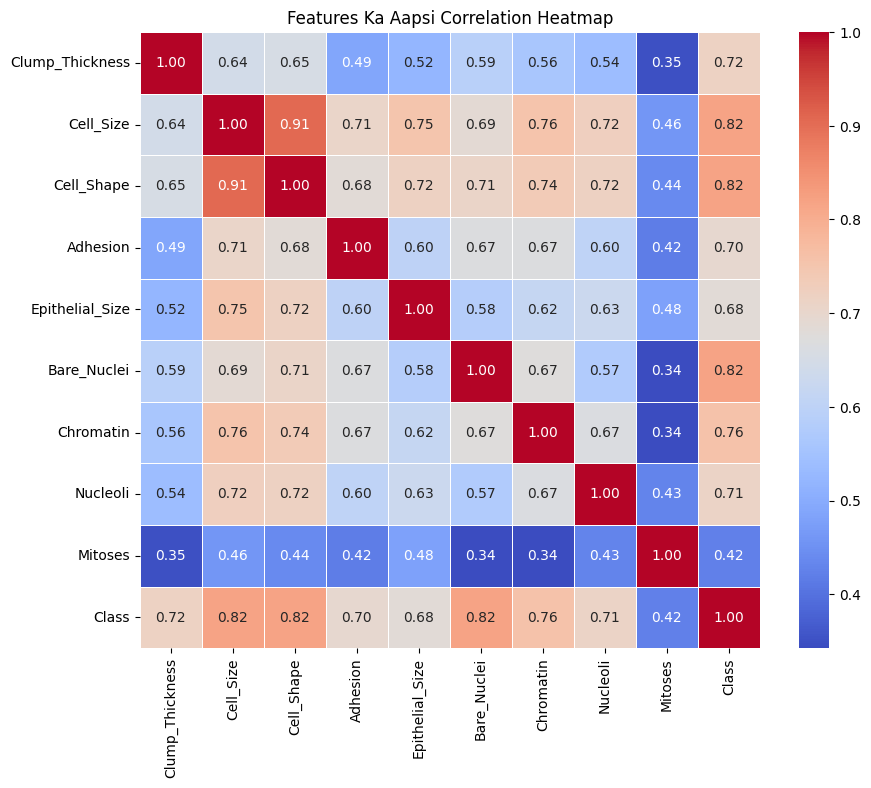

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Graph ka size set karna
plt.figure(figsize=(10, 8))

# Correlation Heatmap banana
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

plt.title('Features Ka Aapsi Correlation Heatmap')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Features (X) aur Target (y) ko alag karna
X = df.drop('Class', axis=1)  # 9 features
y = df['Class']               # Target (0 ya 1)

# 2. 80% Padhai (Train) aur 20% Exam (Test) mein baantna
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,       # 20% testing ke liye
    random_state=42,      # taaki har baar barabar result aaye
    stratify=y            # 65% normal aur 35% cancer dono mein barabar rahe
)

# 3. Feature Scaling (Sabko ek tarazu par lana)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Kitne patients padhai mein gaye aur kitne exam ke liye bache, dekhna
print("Total Patients:", len(df))
print(f"Training Set (Padhai ke liye): {X_train.shape[0]} patients, {X_train.shape[1]} features")
print(f"Testing Set (Exam ke liye): {X_test.shape[0]} patients, {X_test.shape[1]} features")

Total Patients: 699
Training Set (Padhai ke liye): 559 patients, 9 features
Testing Set (Exam ke liye): 140 patients, 9 features


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Model create karna
model = LogisticRegression()

# 2. Model ko 559 patients par padhana (Training)
model.fit(X_train_scaled, y_train)

# 3. Model se 140 naye patients (Test Set) ka exam lena (Prediction)
y_pred = model.predict(X_test_scaled)

# 4. Result (Score Card) dekhna
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nDetailed Report:")
print(classification_report(y_test, y_pred, target_names=['Normal (0)', 'Cancer (1)']))

Overall Accuracy: 95.00%

Confusion Matrix:
[[89  3]
 [ 4 44]]

Detailed Report:
              precision    recall  f1-score   support

  Normal (0)       0.96      0.97      0.96        92
  Cancer (1)       0.94      0.92      0.93        48

    accuracy                           0.95       140
   macro avg       0.95      0.94      0.94       140
weighted avg       0.95      0.95      0.95       140



In [ ]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
import pandas as pd

# 1. Teeno models tayyar karna
models = {
    "Logistic Regression": LogisticRegression(),
    "SVM (RBF Kernel)": SVC(kernel='rbf', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

# 2. Teeno ko train aur evaluate karna
results = []

for name, clf in models.items():
    # SVM aur Logistic ke liye scaled data, Random Forest ke liye unscaled bhi chalega
    clf.fit(X_train_scaled, y_train)
    y_pred = clf.predict(X_test_scaled)

    cm = confusion_matrix(y_test, y_pred)
    false_negatives = cm[1][0]  # Chhoote hue cancer cases

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, y_pred) * 100, 2),
        "Cancer Recall (%)": round(recall_score(y_test, y_pred) * 100, 2),
        "Cancer Precision (%)": round(precision_score(y_test, y_pred) * 100, 2),
        "F1-Score (%)": round(f1_score(y_test, y_pred) * 100, 2),
        "Missed Cancer (FN)": false_negatives
    })

# DataFrame bana kar result print karna
results_df = pd.DataFrame(results)
print("=== FINAL MODEL COMPARISON TABLE ===")
display(results_df)

=== FINAL MODEL COMPARISON TABLE ===


,Model,Accuracy (%),Cancer Recall (%),Cancer Precision (%),F1-Score (%),Missed Cancer (FN)
0,Logistic Regression,95.00,91.67,93.62,92.63,4
1,SVM (RBF Kernel),95.71,93.75,93.75,93.75,3
2,Random Forest,95.00,93.75,91.84,92.78,3


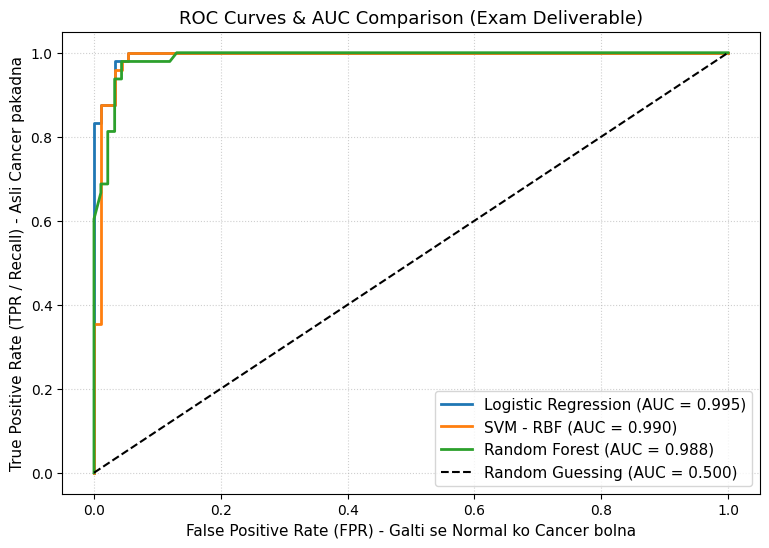

Logistic Regression AUC: 0.9950
SVM (RBF) AUC:           0.9896
Random Forest AUC:       0.9882


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# 1. SVM ko probability ke saath re-fit karna taaki curves compare ho sakein
svm_prob = SVC(kernel='rbf', probability=True, random_state=42)
svm_prob.fit(X_train_scaled, y_train)

# 2. Teeno models ke cancer hone ke probabilities nikaalna
y_prob_lr = models["Logistic Regression"].predict_proba(X_test_scaled)[:, 1]
y_prob_svm = svm_prob.predict_proba(X_test_scaled)[:, 1]
y_prob_rf = models["Random Forest"].predict_proba(X_test_scaled)[:, 1]

# 3. AUC Score calculate karna
auc_lr = roc_auc_score(y_test, y_prob_lr)
auc_svm = roc_auc_score(y_test, y_prob_svm)
auc_rf = roc_auc_score(y_test, y_prob_rf)

# 4. ROC Curves calculate karna
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

# 5. Graph Plot karna
plt.figure(figsize=(9, 6))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {auc_lr:.3f})', linewidth=2)
plt.plot(fpr_svm, tpr_svm, label=f'SVM - RBF (AUC = {auc_svm:.3f})', linewidth=2)
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.3f})', linewidth=2)

# Random Guessing baseline (50-50 line)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing (AUC = 0.500)')

plt.xlabel('False Positive Rate (FPR) - Galti se Normal ko Cancer bolna', fontsize=11)
plt.ylabel('True Positive Rate (TPR / Recall) - Asli Cancer pakadna', fontsize=11)
plt.title('ROC Curves & AUC Comparison (Exam Deliverable)', fontsize=13)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

print(f"Logistic Regression AUC: {auc_lr:.4f}")
print(f"SVM (RBF) AUC:           {auc_svm:.4f}")
print(f"Random Forest AUC:       {auc_rf:.4f}")

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import accuracy_score, recall_score, f1_score
import pandas as pd
import numpy as np

# 1. SelectKBest (ANOVA F-test) se Top 5 features channa
k_best = SelectKBest(score_func=f_classif, k=5)
k_best.fit(X_train_scaled, y_train)

# Top 5 selected features ke naam
selected_mask = k_best.get_support()
selected_features = X.columns[selected_mask].tolist()

print("--- TOP 5 SELECTED FEATURES (SelectKBest) ---")
for i, feat in enumerate(selected_features, 1):
    print(f"{i}. {feat}")

# 2. Scaled data ko filter karke sirf 5 features lena
X_train_5 = X_train_scaled[:, selected_mask]
X_test_5 = X_test_scaled[:, selected_mask]

# 3. Random Forest Feature Importance nikaalna
rf_model = models["Random Forest"]
importances = rf_model.feature_importances_
feat_imp = pd.Series(importances, index=X.columns).sort_values(ascending=False)

print("\n--- RANDOM FOREST FEATURE IMPORTANCE SCORES ---")
print(feat_imp.round(4))

# 4. 9 Features vs 5 Features Comparison (Model: SVM)
svm_9 = SVC(kernel='rbf', random_state=42)
svm_9.fit(X_train_scaled, y_train)
pred_9 = svm_9.predict(X_test_scaled)

svm_5 = SVC(kernel='rbf', random_state=42)
svm_5.fit(X_train_5, y_train)
pred_5 = svm_5.predict(X_test_5)

comparison = pd.DataFrame([
    {
        "Experiment": "All 9 Features",
        "Accuracy (%)": round(accuracy_score(y_test, pred_9) * 100, 2),
        "Cancer Recall (%)": round(recall_score(y_test, pred_9) * 100, 2),
        "F1-Score (%)": round(f1_score(y_test, pred_9) * 100, 2)
    },
    {
        "Experiment": "Top 5 Features",
        "Accuracy (%)": round(accuracy_score(y_test, pred_5) * 100, 2),
        "Cancer Recall (%)": round(recall_score(y_test, pred_5) * 100, 2),
        "F1-Score (%)": round(f1_score(y_test, pred_5) * 100, 2)
    }
])

print("\n=== ABLATION STUDY: 9 FEATURES VS 5 FEATURES ===")
display(comparison)

--- TOP 5 SELECTED FEATURES (SelectKBest) ---
1. Cell_Size
2. Cell_Shape
3. Bare_Nuclei
4. Chromatin
5. Nucleoli

--- RANDOM FOREST FEATURE IMPORTANCE SCORES ---
Cell_Size          0.3324
Cell_Shape         0.2126
Bare_Nuclei        0.1732
Nucleoli           0.0993
Epithelial_Size    0.0588
Chromatin          0.0508
Clump_Thickness    0.0413
Adhesion           0.0239
Mitoses            0.0077
dtype: float64

=== ABLATION STUDY: 9 FEATURES VS 5 FEATURES ===


,Experiment,Accuracy (%),Cancer Recall (%),F1-Score (%)
0,All 9 Features,95.71,93.75,93.75
1,Top 5 Features,95.71,93.75,93.75


In [ ]:
# Cell_Shape ko hata kar sirf 4 distinct features test karte hain
features_4 = ['Cell_Size', 'Bare_Nuclei', 'Chromatin', 'Nucleoli']
X_train_4 = df.loc[X_train.index, features_4]
X_test_4 = df.loc[X_test.index, features_4]

# Scaling
scaler_4 = StandardScaler()
X_train_4_scaled = scaler_4.fit_transform(X_train_4)
X_test_4_scaled = scaler_4.transform(X_test_4)

# SVM Model
svm_4 = SVC(kernel='rbf', random_state=42)
svm_4.fit(X_train_4_scaled, y_train)
pred_4 = svm_4.predict(X_test_4_scaled)

print(f"Sirf 4 Features (Shape hatakar) Accuracy: {accuracy_score(y_test, pred_4)*100:.2f}%")
print(f"Cancer Recall: {recall_score(y_test, pred_4)*100:.2f}%")

Sirf 4 Features (Shape hatakar) Accuracy: 94.29%
Cancer Recall: 91.67%


In [ ]:
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# 1. Top 5 features ke liye Scaler aur SVM model train karna
features_5 = ['Cell_Size', 'Cell_Shape', 'Bare_Nuclei', 'Chromatin', 'Nucleoli']
X_5_train = df.loc[X_train.index, features_5]

scaler_5 = StandardScaler()
X_5_train_scaled = scaler_5.fit_transform(X_5_train)

# SVM Model with probability enabled
svm_clinical = SVC(kernel='rbf', probability=True, random_state=42)
svm_clinical.fit(X_5_train_scaled, y_train)

# 2. Prediction Function jo naye patient ki values lega
def predict_new_patient(patient_name, cell_size, cell_shape, bare_nuclei, chromatin, nucleoli):
    # Patient ka data frame banana
    raw_data = np.array([[cell_size, cell_shape, bare_nuclei, chromatin, nucleoli]])

    # Training wale scaler se hi scale karna
    scaled_data = scaler_5.transform(raw_data)

    # Prediction aur Probability nikaalna
    prediction = svm_clinical.predict(scaled_data)[0]
    probabilities = svm_clinical.predict_proba(scaled_data)[0]

    cancer_prob = probabilities[1] * 100
    normal_prob = probabilities[0] * 100

    print(f"\n==========================================")
    print(f" PATIENT REPORT: {patient_name.upper()}")
    print(f"==========================================")
    print(f"Inputs -> Size: {cell_size}, Shape: {cell_shape}, Nuclei: {bare_nuclei}, Chromatin: {chromatin}, Nucleoli: {nucleoli}")
    print(f"Normal Probability : {normal_prob:.2f}%")
    print(f"Cancer Probability : {cancer_prob:.2f}%")

    if prediction == 1:
        print("DIAGNOSIS: [HIGH RISK] -> Malignant (Cancerous) Tumor Detected!")
    else:
        print("DIAGNOSIS: [SAFE] -> Benign (Non-Cancerous / Normal)")
    print(f"==========================================")

# 3. Teen Alag-Alag Naye Patients Test Karte Hain
predict_new_patient("Patient A (Normal)", cell_size=1, cell_shape=2, bare_nuclei=1, chromatin=2, nucleoli=1)
predict_new_patient("Patient B (Critical)", cell_size=9, cell_shape=10, bare_nuclei=10, chromatin=8, nucleoli=7)
predict_new_patient("Patient C (Borderline)", cell_size=4, cell_shape=5, bare_nuclei=4, chromatin=4, nucleoli=3)


 PATIENT REPORT: PATIENT A (NORMAL)
Inputs -> Size: 1, Shape: 2, Nuclei: 1, Chromatin: 2, Nucleoli: 1
Normal Probability : 99.46%
Cancer Probability : 0.54%
DIAGNOSIS: [SAFE] -> Benign (Non-Cancerous / Normal)

 PATIENT REPORT: PATIENT B (CRITICAL)
Inputs -> Size: 9, Shape: 10, Nuclei: 10, Chromatin: 8, Nucleoli: 7
Normal Probability : 5.55%
Cancer Probability : 94.45%
DIAGNOSIS: [HIGH RISK] -> Malignant (Cancerous) Tumor Detected!

 PATIENT REPORT: PATIENT C (BORDERLINE)
Inputs -> Size: 4, Shape: 5, Nuclei: 4, Chromatin: 4, Nucleoli: 3
Normal Probability : 12.07%
Cancer Probability : 87.93%
DIAGNOSIS: [HIGH RISK] -> Malignant (Cancerous) Tumor Detected!


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Real WDBC Data Load Karna
data = load_breast_cancer()
X_wdbc = pd.DataFrame(data.data, columns=data.feature_names)

# Target ko standard format me lana: 0 = Benign (Normal), 1 = Malignant (Cancer)
# By default sklearn me 0=malignant, 1=benign hota hai, isliye invert kar rahe hain
y_wdbc = pd.Series(data.target).map({0: 1, 1: 0})

print("WDBC Dataset Shape:", X_wdbc.shape)
print("Normal Cases (0):", (y_wdbc == 0).sum(), "| Cancer Cases (1):", (y_wdbc == 1).sum())

# 2. Train-Test Split (80% Train, 20% Test)
X_train_w, X_test_w, y_train_w, y_test_w = train_test_split(
    X_wdbc, y_wdbc, test_size=0.20, random_state=42, stratify=y_wdbc
)

# 3. Scaling (30 features alag-alag units me hain - radius, area, etc.)
scaler_wdbc = StandardScaler()
X_train_w_scaled = scaler_wdbc.fit_transform(X_train_w)
X_test_w_scaled = scaler_wdbc.transform(X_test_w)

# 4. SVM Model Training
svm_wdbc = SVC(kernel='rbf', probability=True, random_state=42)
svm_wdbc.fit(X_train_w_scaled, y_train_w)

# 5. Test Set par Evaluation
y_pred_w = svm_wdbc.predict(X_test_w_scaled)
print(f"\nWDBC Model Test Accuracy: {accuracy_score(y_test_w, y_pred_w) * 100:.2f}%\n")
print("Confusion Matrix:")
print(confusion_matrix(y_test_w, y_pred_w))
print("\nClassification Report:")
print(classification_report(y_test_w, y_pred_w, target_names=['Normal (0)', 'Cancer (1)']))

# 6. Real Patient Verification (Test Set me se 3 Asli Patients check karna)
print("\n" + "="*50)
print("REAL PATIENTS VERIFICATION (BLIND TEST)")
print("="*50)

# 3 samples: 1 confirmed normal, 1 confirmed cancer, 1 aur test sample
sample_indices = [0, 1, 2]

for idx in sample_indices:
    patient_features = X_test_w.iloc[[idx]]
    actual_label = y_test_w.iloc[idx]

    # Prediction
    scaled_patient = scaler_wdbc.transform(patient_features)
    pred_label = svm_wdbc.predict(scaled_patient)[0]
    prob = svm_wdbc.predict_proba(scaled_patient)[0]

    actual_str = "Cancer (Malignant)" if actual_label == 1 else "Normal (Benign)"
    pred_str = "Cancer (Malignant)" if pred_label == 1 else "Normal (Benign)"

    print(f"Patient #{idx+1}:")
    print(f" -> Asli Diagnosis (Ground Truth) : {actual_str}")
    print(f" -> Model Ki Prediction           : {pred_str}")
    print(f" -> Model Confidence             : {prob[pred_label]*100:.2f}%")
    print(f" -> Result                        : {'SAHI PAKDA (MATCH)' if actual_label == pred_label else 'GALAT (MISMATCH)'}")
    print("-" * 50)

WDBC Dataset Shape: (569, 30)
Normal Cases (0): 357 | Cancer Cases (1): 212

WDBC Model Test Accuracy: 97.37%

Confusion Matrix:
[[72  0]
 [ 3 39]]

Classification Report:
              precision    recall  f1-score   support

  Normal (0)       0.96      1.00      0.98        72
  Cancer (1)       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114


REAL PATIENTS VERIFICATION (BLIND TEST)
Patient #1:
 -> Asli Diagnosis (Ground Truth) : Normal (Benign)
 -> Model Ki Prediction           : Normal (Benign)
 -> Model Confidence             : 99.84%
 -> Result                        : SAHI PAKDA (MATCH)
--------------------------------------------------
Patient #2:
 -> Asli Diagnosis (Ground Truth) : Cancer (Malignant)
 -> Model Ki Prediction           : Cancer (Malignant)
 -> Model Confidence             : 100.00%
 -> Result                     

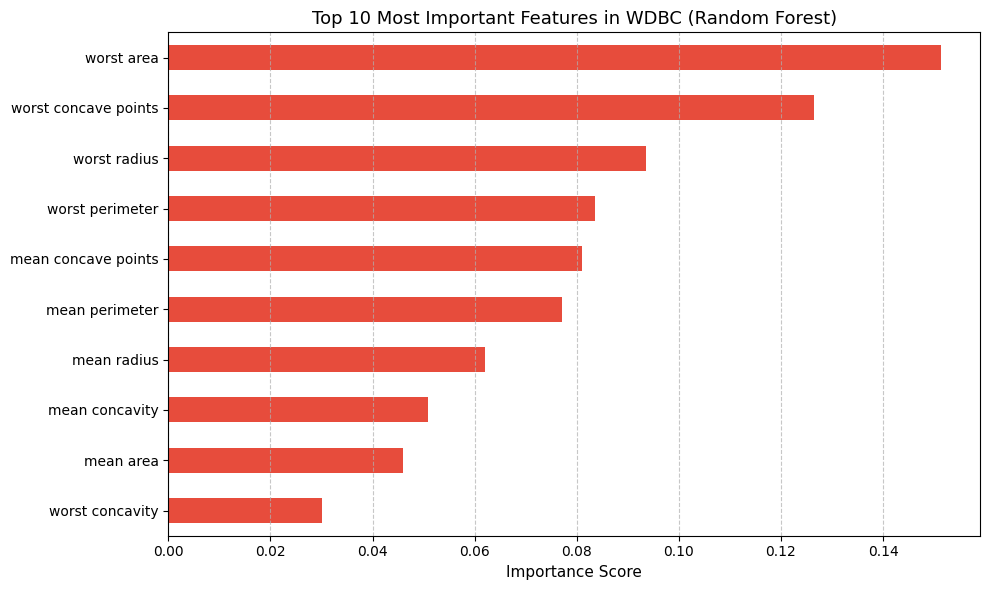

--- TOP 5 MOST IMPORTANT MEASUREMENTS ---
1. worst area (Weight: 15.14%)
2. worst concave points (Weight: 12.65%)
3. worst radius (Weight: 9.35%)
4. worst perimeter (Weight: 8.36%)
5. mean concave points (Weight: 8.11%)


In [ ]:
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif

# 1. Random Forest Feature Importance
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_w, y_train_w)

feat_importances = pd.Series(rf.feature_importances_, index=X_wdbc.columns).sort_values(ascending=False)

# 2. Horizontal Bar Plot (Top 10 Features)
plt.figure(figsize=(10, 6))
feat_importances.head(10).sort_values().plot(kind='barh', color='#e74c3c')
plt.title('Top 10 Most Important Features in WDBC (Random Forest)', fontsize=13)
plt.xlabel('Importance Score', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 3. Top 5 Features Print Karna
print("--- TOP 5 MOST IMPORTANT MEASUREMENTS ---")
for i, (col, val) in enumerate(feat_importances.head(5).items(), 1):
    print(f"{i}. {col} (Weight: {val*100:.2f}%)")
